# 02 · Modelos: ¿cuántos viajeros esperar y quién se aloja en hotel?

**Para:** Gerencia Comercial y Técnica · **Metodología:** CRISP-DM — este notebook cubre las fases **3. Preparación de datos**, **4. Modelado** y **5. Evaluación** (las fases 1 y 2, negocio y datos, están en `01_eda.ipynb`; la conclusión, en `03_conclusiones.ipynb`).

**Lo que responde este notebook, en una línea cada uno:**

1. **Pronóstico de demanda.** Con el contexto económico de los hogares, el modelo elegido (**Random Forest**) se equivoca en promedio **±6,0 %** de los viajeros de cada mes, contra **±6,3 %** de lo que se haría “a ojo” (repetir el mismo mes del año anterior). La ventaja aparece justo en los años de crisis, que es cuando más plata hay en juego.
2. **¿Qué turista se aloja en hotel?** Un clasificador sobre la encuesta de hogares (EVyTH) separa bien a quienes van a hotel (AUC 0,78) y deja reglas simples para dirigir promociones: **viaje de ocio al interior del país, sin auto propio y de hogares de ingresos altos → 2 de cada 3 van a hotel**, casi el triple del promedio (24 %).

| Pregunta de negocio | Tipo de aprendizaje | Variable objetivo (*target*) | Datos |
|---|---|---|---|
| ¿Cuántos viajeros residentes se van a alojar el mes *m*? | Supervisado · **regresión** | Variación interanual de viajeros (%) | EOH (INDEC) + macro (INDEC, BCRA) · mensual |
| ¿Este viaje se aloja en hotel? | Supervisado · **clasificación** | Hotel sí/no | EVyTH (microdatos) · por viaje |

> **Cómo leer los errores.** **MAPE** (error porcentual absoluto medio) = “en promedio, nos equivocamos en ±X % de los viajeros del mes”. **MAE** (error absoluto medio) = lo mismo en unidades (viajeros o puntos porcentuales). **AUC** = probabilidad de que el modelo le ponga más puntaje a un viaje que sí fue a hotel que a uno que no (0,5 = azar, 1 = perfecto).

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

IMG = RAIZ / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 17, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})
# paleta fija: cada cosa siempre del mismo color
AZUL, NARANJA, AQUA, GRIS, GRIS_CLARO = "#2a78d6", "#eb6834", "#1baf7a", "#6b6a66", "#c9c8c2"

def miles(x):
    """1234567 -> '1.234.567' (formato argentino)."""
    return f"{x:,.0f}".replace(",", ".")

def millones(x, dec=2):
    return f"{x / 1e6:.{dec}f}".replace(".", ",") + " M"

def pct(x, dec=1, signo=False):
    s = f"{x:+.{dec}f}" if signo else f"{x:.{dec}f}"
    return s.replace(".", ",") + " %"

fmt_miles = mticker.FuncFormatter(lambda x, _: miles(x))
fmt_millones = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}".replace(".", ",") + " M")

from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

from modelos import (ANIOS_BACKTEST, FEATURES, FEATURES_HOTEL, NOMBRES, PROCESSED, SEMILLA, TARGET, a_viajeros,
                     cargar, cargar_evyth, cargar_mensual, datos_hotel, mape, modelos_demanda, utilizables)

## Fase 3 · Preparación de los datos

### Por qué predecimos la **variación** y no la cantidad de viajeros

La cantidad de viajeros de un mes depende sobre todo de **qué mes es** y de **cuántos viajaron el año pasado**. Lo que la economía cambia es **cuánto más o menos** viaja la gente respecto del año anterior. Por eso el modelo aprende:

> **variación interanual de viajeros (%) = f(cómo cambió la macro en los últimos 12 meses, mes del año)**

y el número de viajeros se reconstruye así: **viajeros del mes = mismo mes del año anterior × (1 + variación predicha)**.

Ventajas para el negocio:

- **Arranca de lo que la gerencia ya hace** (“mirar el mismo mes del año pasado”) y le agrega el ajuste por contexto económico. Si el modelo predice variación 0, da exactamente el número “a ojo”: nunca puede ser peor por diseño de la fórmula, solo por equivocarse en el ajuste.
- **Las variaciones se mantienen dentro del rango histórico** (–24 % a +29 %), mientras que el nivel de viajeros cambia de escala con los años. Esto importa porque los árboles **no extrapolan** (ver más abajo).

### Lo que probamos y no funcionó

La primera versión predecía **directamente la cantidad de viajeros** con las mismas variables. Entrenando hasta 2022 y probando en 2023–2025, **todos los modelos perdieron contra la línea base**:

| Enfoque | MAPE 2023–2025 |
|---|---|
| Línea base “mismo mes año anterior” | **8,5 %** |
| Modelos prediciendo el nivel (lineal, árbol, RF, boosting) | 9,5 % a 12 % |

El motivo: el nivel de viajeros 2023–2025 quedó por debajo de casi todo lo visto en el entrenamiento, y un modelo de árboles solo puede devolver valores que ya vio. Cambiar el *target* a variación interanual resolvió el problema. Lo contamos porque **un modelo que no le gana a la regla simple no sirve, aunque sea más sofisticado**.

In [2]:
df = cargar_mensual()
d = utilizables(df)

FUENTE = {"mes": "Calendario", "salario_real_var": "INDEC (índice de salarios / IPC)", "inflacion_log": "INDEC (IPC)",
          "desocupacion_var": "INDEC (EPH)", "tipo_cambio_real_var": "BCRA (A3500) / IPC", "emae_interanual": "INDEC (EMAE)"}
tabla_features = pd.DataFrame({
    "Variable": FEATURES,
    "Qué mide": [NOMBRES[f] for f in FEATURES],
    "Fuente": [FUENTE[f] for f in FEATURES],
    "Mínimo": d[FEATURES].min().round(1).values,
    "Mediana": d[FEATURES].median().round(1).values,
    "Máximo": d[FEATURES].max().round(1).values,
})
tabla_features.loc[len(tabla_features)] = ["var_viajeros (target)", "Variación interanual de viajeros residentes (%)",
                                           "INDEC (EOH)", *d.var_viajeros.agg(["min", "median", "max"]).round(1)]
print(f"Meses en el dataset: {len(df)} ({df.index.min():%Y-%m} a {df.index.max():%Y-%m})")
print(f"Meses utilizables para entrenar/evaluar: {len(d)}  "
      f"(se excluyen la pandemia 2020-03→2021-12 y los 12 meses siguientes, cuya referencia es pandemia)")
tabla_features

Meses en el dataset: 227 (2007-01 a 2025-11)
Meses utilizables para entrenar/evaluar: 181  (se excluyen la pandemia 2020-03→2021-12 y los 12 meses siguientes, cuya referencia es pandemia)


,Variable,Qué mide,Fuente,Mínimo,Mediana,Máximo
0,mes,Mes del año,Calendario,1.0,6.0,12.0
1,salario_real_var,Variación del salario real (%),INDEC (índice de salarios / IPC),-19.1,1.3,11.9
2,inflacion_log,Inflación interanual (log),INDEC (IPC),2.6,3.4,5.7
3,desocupacion_var,Cambio en la desocupación (p.p.),INDEC (EPH),-1.6,-0.1,2.7
4,tipo_cambio_real_var,Variación del tipo de cambio real (%),BCRA (A3500) / IPC,-30.9,-5.3,59.2
5,emae_interanual,"Actividad económica, var. interanual (%)",INDEC (EMAE),-10.2,0.4,14.8
6,var_viajeros (target),Variación interanual de viajeros residentes (%),INDEC (EOH),-24.2,0.9,29.1


**Qué leemos.** Seis predictores, todos **cambios de los últimos 12 meses**, así hablan el mismo idioma que el *target*. La inflación entra en logaritmo porque pasar de 25 % a 50 % pesa mucho más que pasar de 250 % a 275 %. La pobreza no entra: tiene huecos en 2007–2016 (ver EDA).

### Esquema de validación: siempre se predice el futuro con el pasado

**Validación *walk-forward*** (hacia adelante): para cada año de prueba, el modelo se entrena **solo con los años anteriores** y predice los 12 meses de ese año. Nunca ve el futuro. Se repite para 9 años distintos, así medimos el error en **varias particiones** y no en una sola que podría ser “fácil” o “difícil” por casualidad.

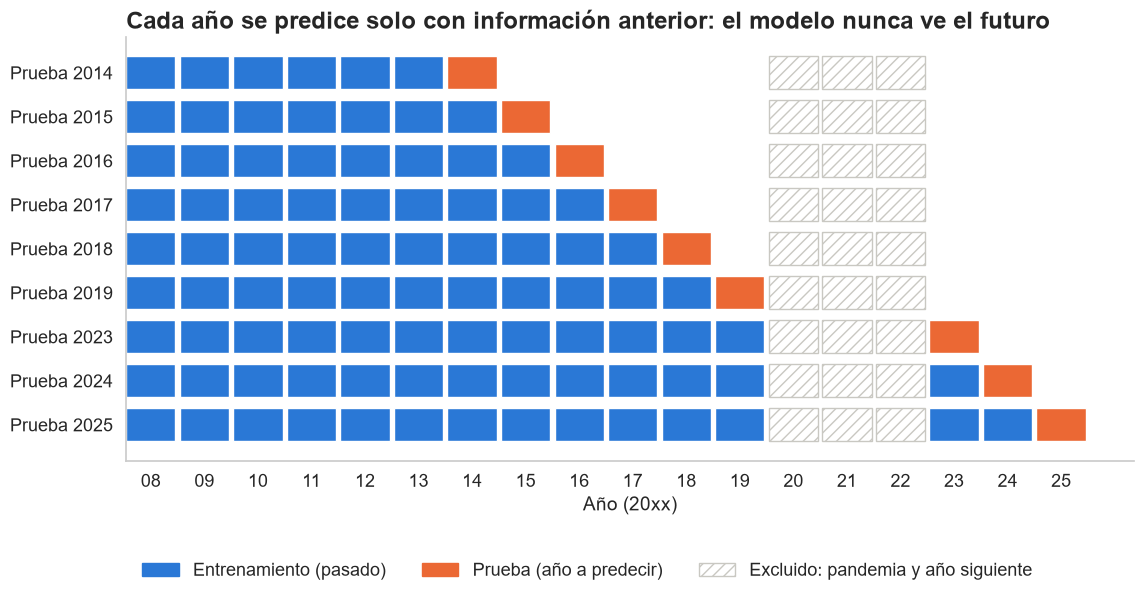

In [3]:
fig, ax = plt.subplots(figsize=(13, 5.5))
anios = np.arange(2008, 2026)
for fila, anio_test in enumerate(ANIOS_BACKTEST):
    for anio in anios:
        if 2020 <= anio <= 2022:
            color, hatch = "white", "///"
        elif anio < anio_test:
            color, hatch = AZUL, None
        elif anio == anio_test:
            color, hatch = NARANJA, None
        else:
            continue
        ax.barh(fila, 0.92, left=anio - 0.46, color=color, edgecolor=GRIS_CLARO if hatch else "white",
                hatch=hatch, height=0.75)
ax.set_yticks(range(len(ANIOS_BACKTEST)), [f"Prueba {a}" for a in ANIOS_BACKTEST])
ax.invert_yaxis()
ax.set_xticks(anios, [str(a)[2:] for a in anios])
ax.set_xlabel("Año (20xx)")
ax.grid(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Entrenamiento (pasado)"), Patch(color=NARANJA, label="Prueba (año a predecir)"),
                   Patch(facecolor="white", edgecolor=GRIS_CLARO, hatch="///", label="Excluido: pandemia y año siguiente")],
          loc="lower left", bbox_to_anchor=(0, -0.32), ncol=3, frameon=False)
ax.set_title("Cada año se predice solo con información anterior: el modelo nunca ve el futuro")
plt.show()

## Fases 4 y 5 · Modelado y evaluación del pronóstico de demanda

Comparamos cinco modelos con el mismo esquema:

| Modelo | Idea en una línea | Rol |
|---|---|---|
| **Línea base** | Mismo mes del año anterior (variación 0) | El **piso**: lo que se haría a ojo |
| **Regresión lineal** | Cada variable suma o resta en línea recta | Interpretable y **extrapola** |
| **Árbol de decisión** | Preguntas sí/no encadenadas → reglas | **Explicar** a la gerencia |
| **Random Forest** | Promedio de 500 árboles, cada uno con datos y variables al azar (*bagging*) | **Precisión** y estabilidad |
| **Gradient Boosting** | Árboles chicos en secuencia, cada uno corrige al anterior | Alternativa de precisión |

### Resultado del *backtest*: error por año (MAPE, %)

In [4]:
tabla = pd.read_csv(PROCESSED / "backtest_mape.csv", index_col=0)
tabla.columns = [c if c == "Promedio" else int(c) for c in tabla.columns]
años = [a for a in tabla.columns if a != "Promedio"]
BASE = "Baseline (mismo mes año anterior)"
resumen = tabla.copy()
resumen["Años que le gana al baseline"] = [(tabla.loc[m, años] < tabla.loc[BASE, años]).sum() if m != BASE else np.nan
                                           for m in tabla.index]
resumen.round(1)

,2014,2015,2016,2017,2018,2019,2023,2024,2025,Promedio,Años que le gana al baseline
Random Forest,6.0,3.9,5.7,6.0,3.5,2.6,7.9,14.4,3.8,6.0,6.0
Baseline (mismo mes año anterior),4.4,4.5,5.7,7.4,5.2,4.0,5.7,14.8,4.8,6.3,NaN
Gradient Boosting,6.4,4.0,5.4,7.0,3.7,3.4,8.1,13.5,5.3,6.3,6.0
Árbol de decisión,6.2,4.5,5.5,6.8,4.2,3.5,8.1,15.4,4.7,6.6,6.0
Regresión lineal,10.9,3.4,6.3,5.5,4.1,4.2,26.9,14.4,3.9,8.9,5.0


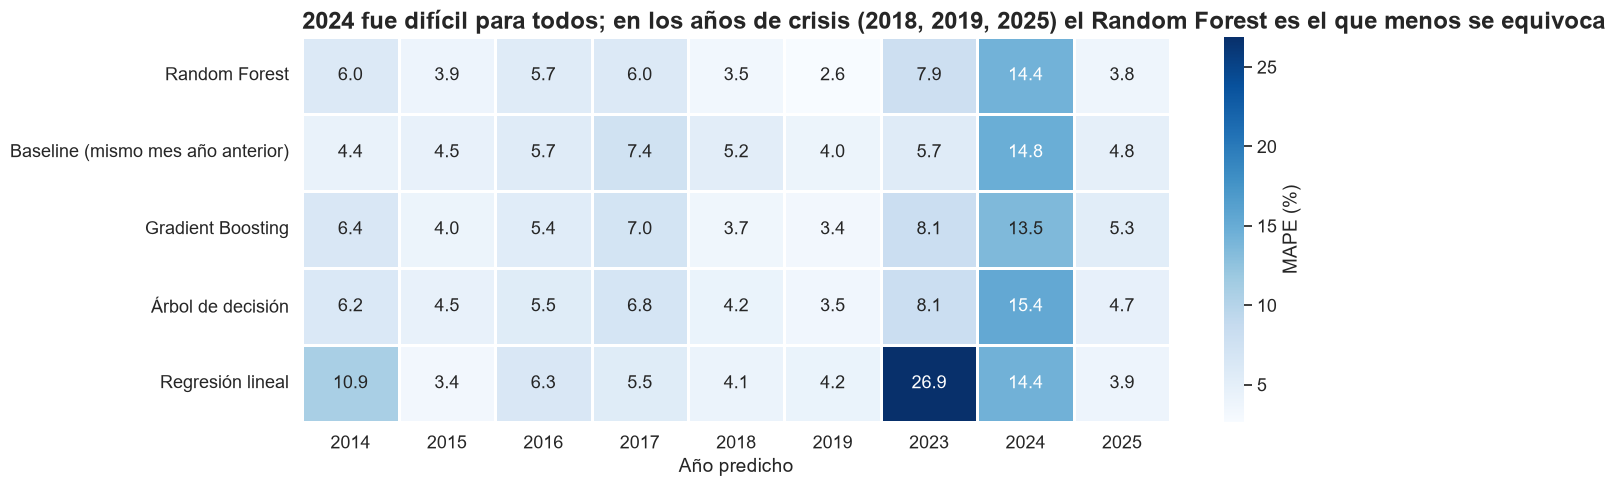

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(tabla[años], annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "MAPE (%)"}, linewidths=2,
            linecolor="white", annot_kws={"size": 13}, ax=ax)
ax.set_xlabel("Año predicho"); ax.set_ylabel("")
ax.set_title("2024 fue difícil para todos; en los años de crisis (2018, 2019, 2025) el Random Forest es el que menos se equivoca")
plt.show()

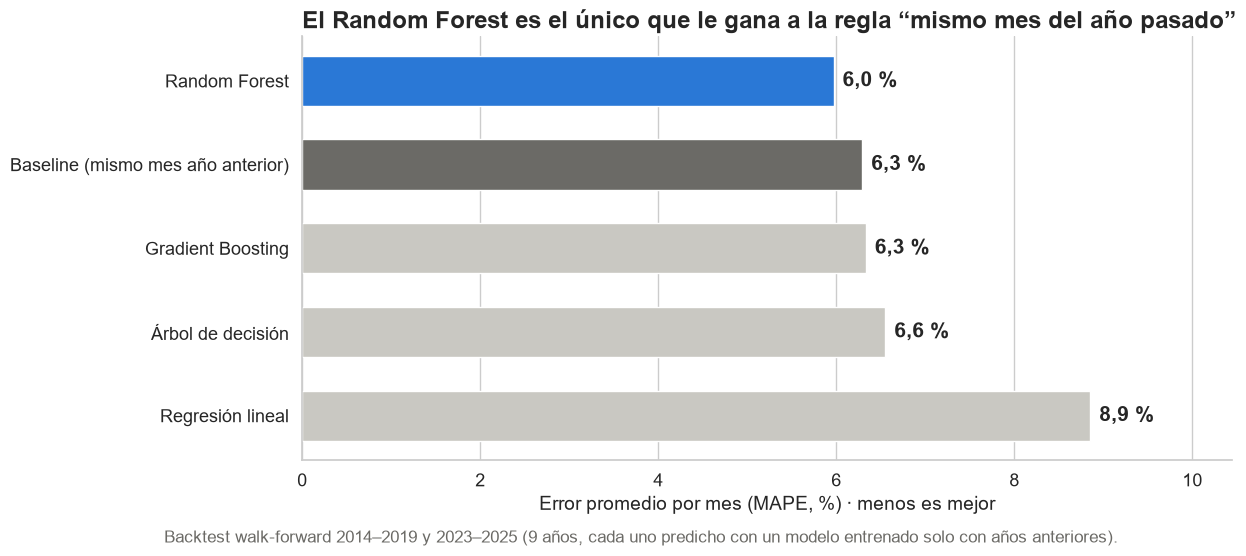

In [6]:
orden = tabla["Promedio"].sort_values()
colores = [AZUL if m == "Random Forest" else (GRIS if m == BASE else GRIS_CLARO) for m in orden.index]
fig, ax = plt.subplots(figsize=(12, 5.5))
barras = ax.barh(orden.index, orden.values, color=colores, height=0.6)
for b, v in zip(barras, orden.values):
    ax.text(v + 0.1, b.get_y() + b.get_height() / 2, pct(v), va="center", fontsize=15, fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Error promedio por mes (MAPE, %) · menos es mejor")
ax.set_xlim(0, orden.max() * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("El Random Forest es el único que le gana a la regla “mismo mes del año pasado”")
fig.text(0.01, -0.04, "Backtest walk-forward 2014–2019 y 2023–2025 (9 años, cada uno predicho con un modelo entrenado solo con años anteriores).",
         fontsize=12, color=GRIS)
fig.savefig(IMG / "mape_por_modelo.png")
plt.show()

**Qué leemos.**

- **Random Forest: 6,0 %** de error promedio contra **6,3 %** de la línea base. Parece poco, pero le gana en **los años en que la economía se movió fuerte** (2017, 2018, 2019, 2025), que son justamente los años en que el número “a ojo” deja a la empresa con personal o cupos de más o de menos.
- **Gradient Boosting (6,3 %)** empata con la línea base: más complejo no siempre es mejor (“medir antes de complicarse”).
- **Regresión lineal (8,9 %)** es la peor en promedio por un solo año: en **2023** se equivoca 27 %. Una línea recta extrapola sin freno cuando la macro sale del rango conocido.
- **2024** (≈14 % de error en todos): la caída de la demanda fue más brusca de lo que la macro anticipaba, y además se comparaba con un 2023 inflado por PreViaje.

### Real vs. modelo vs. regla simple, 2023–2025

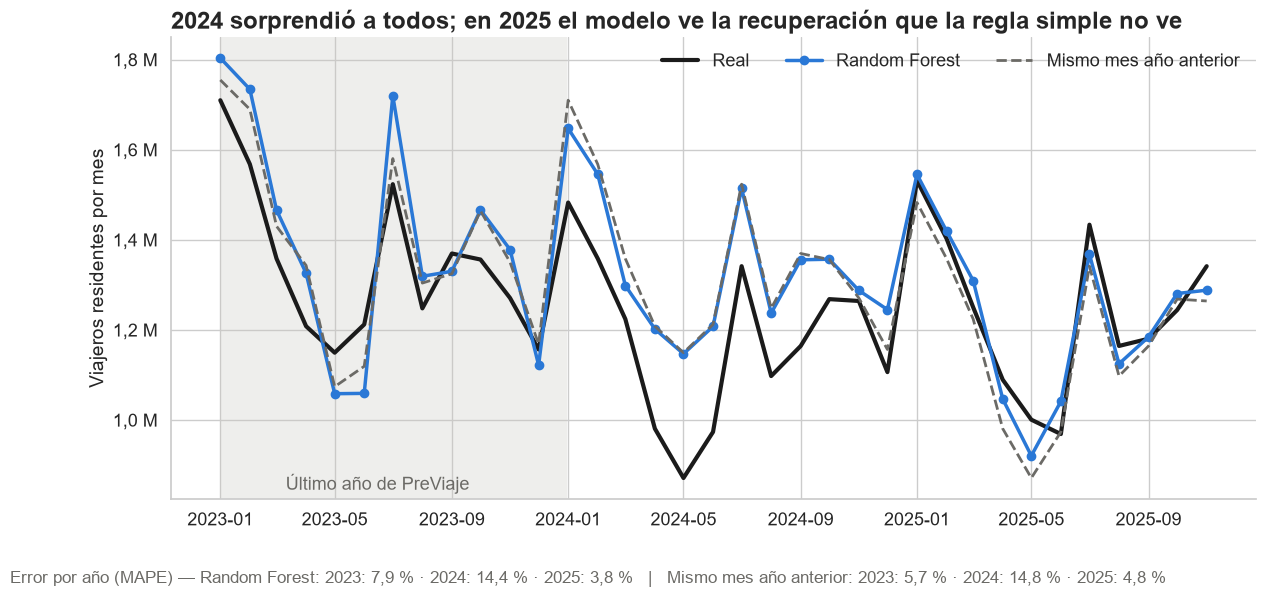

Sesgo medio (predicción vs real, %; positivo = el modelo esperaba más viajeros de los que hubo):


modelo,Random Forest,Baseline (mismo mes año anterior)
fecha,,
2023,3.5,2.7
2024,14.4,14.8
2025,-0.6,-4.4


In [7]:
preds = pd.read_csv(PROCESSED / "backtest_predicciones.csv", parse_dates=["fecha"])
ventana = preds[preds.fecha >= "2023-01-01"]
real = ventana.drop_duplicates("fecha").set_index("fecha")["real"]
rf_pred = ventana[ventana.modelo == "Random Forest"].set_index("fecha")["prediccion"]
base_pred = ventana[ventana.modelo == BASE].set_index("fecha")["prediccion"]

fig, ax = plt.subplots(figsize=(14, 6))
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color=GRIS_CLARO, alpha=0.3, lw=0)
ax.text(pd.Timestamp("2023-06-15"), real.min() * 0.97, "Último año de PreViaje", fontsize=13, color=GRIS, ha="center")
ax.plot(real.index, real, color="#1b1b1b", lw=3, label="Real")
ax.plot(rf_pred.index, rf_pred, color=AZUL, lw=2.5, marker="o", ms=6, label="Random Forest")
ax.plot(base_pred.index, base_pred, color=GRIS, lw=2, ls="--", label="Mismo mes año anterior")
ax.yaxis.set_major_formatter(fmt_millones)
ax.set_ylabel("Viajeros residentes por mes")
ax.legend(loc="upper right", ncol=3, frameon=False)
err_rf = {a: tabla.loc["Random Forest", a] for a in [2023, 2024, 2025]}
err_bl = {a: tabla.loc[BASE, a] for a in [2023, 2024, 2025]}
ax.set_title("2024 sorprendió a todos; en 2025 el modelo ve la recuperación que la regla simple no ve")
fig.text(0.01, -0.03, "Error por año (MAPE) — Random Forest: " + " · ".join(f"{a}: {pct(err_rf[a])}" for a in err_rf)
         + "   |   Mismo mes año anterior: " + " · ".join(f"{a}: {pct(err_bl[a])}" for a in err_bl),
         fontsize=12, color=GRIS)
fig.savefig(IMG / "real_vs_modelo_2023_2025.png")
plt.show()

sesgo = ((ventana.prediccion / ventana.real - 1) * 100).groupby([ventana.fecha.dt.year, ventana.modelo]).mean().unstack()
print("Sesgo medio (predicción vs real, %; positivo = el modelo esperaba más viajeros de los que hubo):")
sesgo[["Random Forest", BASE]].round(1)

**Qué leemos.** En **2023 y 2024** ambos esperaban **más** viajeros de los que hubo: el punto de partida (2022 y 2023) estaba inflado por el rebote post-pandemia y por **PreViaje**, un subsidio que la macro no ve. En **2025** la regla simple se queda corta (esperaba menos viajeros que los reales) y el Random Forest casi no tiene sesgo: leyó la recuperación del salario real.

### Árbol de decisión: ¿qué profundidad?

Un árbol más profundo memoriza mejor el pasado (el error de entrenamiento baja siempre), pero a partir de cierto punto **empeora al predecir años nuevos**: eso es *overfitting*. Elegimos la profundidad **con el gráfico, no con la intuición**: la que da menor error en los años de prueba.

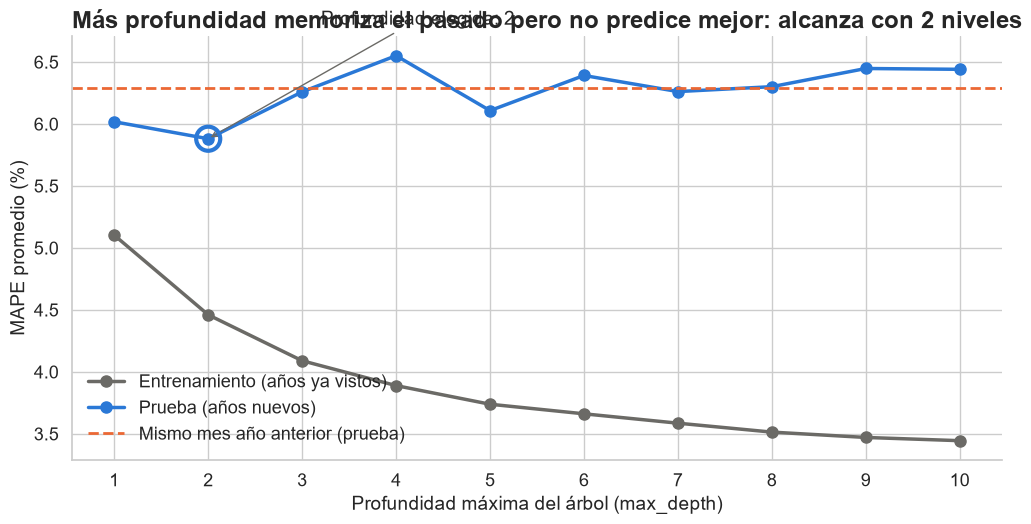

profundidad,1,2,3,4,5,6,7,8,9,10
Entrenamiento,5.10,4.46,4.09,3.89,3.74,3.66,3.59,3.51,3.47,3.44
Prueba,6.02,5.88,6.26,6.55,6.11,6.39,6.26,6.30,6.45,6.44


In [8]:
def curva_profundidad(profundidades):
    filas = []
    for p in profundidades:
        for anio in ANIOS_BACKTEST:
            train, test = d[d.index.year < anio], d[d.index.year == anio]
            m = DecisionTreeRegressor(max_depth=p, min_samples_leaf=5, random_state=SEMILLA)
            m.fit(train[FEATURES], train.var_viajeros)
            filas.append({"profundidad": p, "anio": anio,
                          "Entrenamiento": mape(train[TARGET], a_viajeros(train, m.predict(train[FEATURES]))),
                          "Prueba": mape(test[TARGET], a_viajeros(test, m.predict(test[FEATURES])))})
    return pd.DataFrame(filas)

curva_det = curva_profundidad(range(1, 11))
curva = curva_det.groupby("profundidad")[["Entrenamiento", "Prueba"]].mean()
PROF = int(curva["Prueba"].idxmin())

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(curva.index, curva["Entrenamiento"], color=GRIS, lw=2.5, marker="o", ms=8, label="Entrenamiento (años ya vistos)")
ax.plot(curva.index, curva["Prueba"], color=AZUL, lw=2.5, marker="o", ms=8, label="Prueba (años nuevos)")
ax.axhline(tabla.loc[BASE, "Promedio"], color=NARANJA, ls="--", lw=2, label="Mismo mes año anterior (prueba)")
ax.scatter([PROF], [curva.loc[PROF, "Prueba"]], s=300, facecolor="none", edgecolor=AZUL, lw=3, zorder=5)
ax.annotate(f"Profundidad elegida: {PROF}", (PROF, curva.loc[PROF, "Prueba"]), xytext=(PROF + 1.2, curva["Prueba"].max() + 0.25),
            fontsize=14, arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set_xlabel("Profundidad máxima del árbol (max_depth)")
ax.set_ylabel("MAPE promedio (%)")
ax.set_xticks(curva.index)
ax.legend(frameon=False, loc="lower left")
ax.set_title(f"Más profundidad memoriza el pasado pero no predice mejor: alcanza con {PROF} niveles")
plt.show()
curva.round(2).T

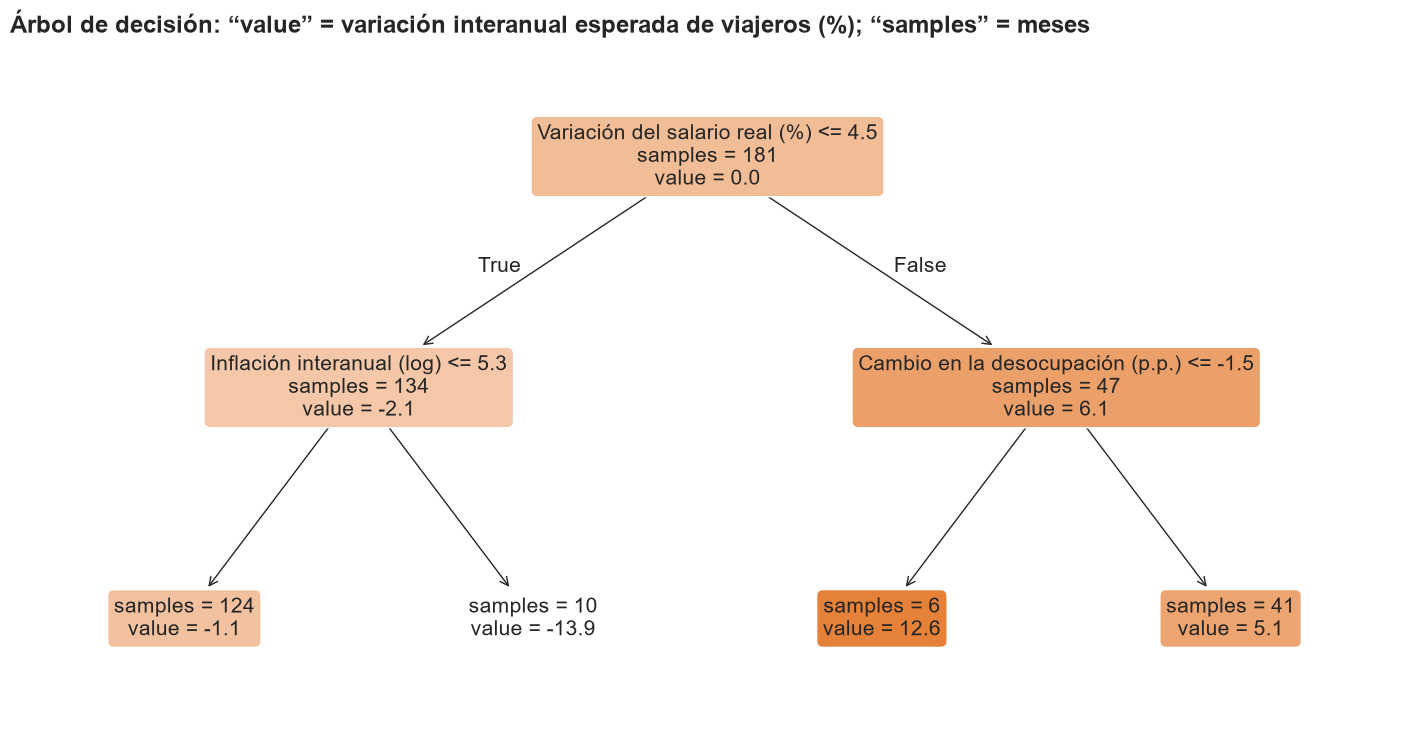

In [9]:
arbol = DecisionTreeRegressor(max_depth=PROF, min_samples_leaf=5, random_state=SEMILLA).fit(d[FEATURES], d.var_viajeros)
fig, ax = plt.subplots(figsize=(18, 4 + 2.5 * PROF))
plot_tree(arbol, feature_names=[NOMBRES[f] for f in FEATURES], filled=True, rounded=True, precision=1,
          impurity=False, fontsize=15 if PROF <= 2 else 12, ax=ax)
ax.set_title("Árbol de decisión: “value” = variación interanual esperada de viajeros (%); “samples” = meses", fontsize=17)
plt.show()

In [10]:
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre",
         "noviembre", "diciembre"]

def hojas(arbol, columnas):
    """Recorre el árbol y devuelve, por hoja, el intervalo (desde, hasta] de cada variable usada."""
    t = arbol.tree_
    salida = []
    def recorrer(nodo, condiciones):
        if t.children_left[nodo] == -1:
            salida.append((nodo, condiciones)); return
        f, u = columnas[t.feature[nodo]], t.threshold[nodo]
        lo, hi = condiciones.get(f, (-np.inf, np.inf))
        recorrer(t.children_left[nodo], {**condiciones, f: (lo, min(hi, u))})
        recorrer(t.children_right[nodo], {**condiciones, f: (max(lo, u), hi)})
    recorrer(0, {})
    return salida

def num(x):
    return f"{x:.1f}".replace(".", ",")

def condicion_demanda(f, lo, hi):
    if f == "mes":
        m = [MESES[i - 1] for i in range(1, 13) if lo < i <= hi]
        return f"el mes es de {m[0]} a {m[-1]}"
    if f == "inflacion_log":
        lo, hi = (v if np.isinf(v) else np.expm1(v) for v in (lo, hi))
        nombre = "la inflación interanual"
    else:
        nombre = NOMBRES[f].split(" (")[0].lower().replace("variación", "la variación").replace("cambio", "el cambio").replace("actividad", "la actividad")
    unidad = " p.p." if f == "desocupacion_var" else " %"
    if np.isinf(lo):
        return f"{nombre} es ≤ {num(hi)}{unidad}"
    if np.isinf(hi):
        return f"{nombre} es > {num(lo)}{unidad}"
    return f"{nombre} está entre {num(lo)} y {num(hi)}{unidad}"

filas = []
for nodo, cond in hojas(arbol, FEATURES):
    valor = arbol.tree_.value[nodo][0][0]
    filas.append({"Regla (si … entonces …)": "Si " + " y ".join(condicion_demanda(f, *v) for f, v in cond.items())
                  + f" → los viajeros {'crecen' if valor >= 0 else 'caen'} {num(abs(valor))} % contra el mismo mes del año anterior",
                  "Meses históricos": arbol.tree_.n_node_samples[nodo]})
reglas_demanda = pd.DataFrame(filas).sort_values("Meses históricos", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(reglas_demanda.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "14px"}))

Regla (si … entonces …),Meses históricos
"Si la variación del salario real es ≤ 4,5 % y la inflación interanual es ≤ 200,8 % → los viajeros caen 1,1 % contra el mismo mes del año anterior",124
"Si la variación del salario real es > 4,5 % y el cambio en la desocupación es > -1,5 p.p. → los viajeros crecen 5,1 % contra el mismo mes del año anterior",41
"Si la variación del salario real es ≤ 4,5 % y la inflación interanual es > 200,8 % → los viajeros caen 13,9 % contra el mismo mes del año anterior",10
"Si la variación del salario real es > 4,5 % y el cambio en la desocupación es ≤ -1,5 p.p. → los viajeros crecen 12,6 % contra el mismo mes del año anterior",6


**Qué leemos.** El árbol resume la historia en pocas reglas que cualquier gerente puede chequear con el diario: **la variable que más separa es el salario real** y, cuando el salario no crece, **la inflación alta** marca los años de caída. Es el modelo que usamos para **explicar**; para **predecir** usamos el Random Forest (ver comparación más abajo).

### Random Forest: validación *out-of-bag* e importancia de variables

Cada uno de los 500 árboles se entrena con una muestra al azar de los meses (*bootstrap*); los meses que le quedaron afuera (≈37 %) sirven para medirlo gratis: es el **OOB score**. El conjunto de prueba sigue siendo el *backtest*.

In [11]:
rf = cargar("demanda_rf.joblib")  # entrenado con todos los meses utilizables (src/entrenar.py)
nivel_oob = a_viajeros(d, rf.oob_prediction_)
print(f"Árboles: {rf.n_estimators} · meses de entrenamiento: {len(d)}")
print(f"OOB R² sobre la variación interanual: {rf.oob_score_:.2f}  "
      f"(explica ~{rf.oob_score_:.0%} de las subidas y bajadas interanuales en meses que cada árbol no vio)")
print(f"OOB MAPE en viajeros: {pct(mape(d[TARGET], nivel_oob))}  vs.  mismo mes año anterior: "
      f"{pct(mape(d[TARGET], d.viajeros_anio_anterior))}")

Árboles: 500 · meses de entrenamiento: 181
OOB R² sobre la variación interanual: 0.37  (explica ~37% de las subidas y bajadas interanuales en meses que cada árbol no vio)
OOB MAPE en viajeros: 4,7 %  vs.  mismo mes año anterior: 6,1 %


**Importancia por permutación** (no la importancia “MDI” que trae el modelo, que favorece a variables con muchos valores distintos): en cada año de prueba **desordenamos una variable** y medimos cuánto empeora el error. Si empeora mucho, el modelo depende de esa variable. Se promedia sobre los 9 años del *backtest*, siempre con datos que el modelo no vio.

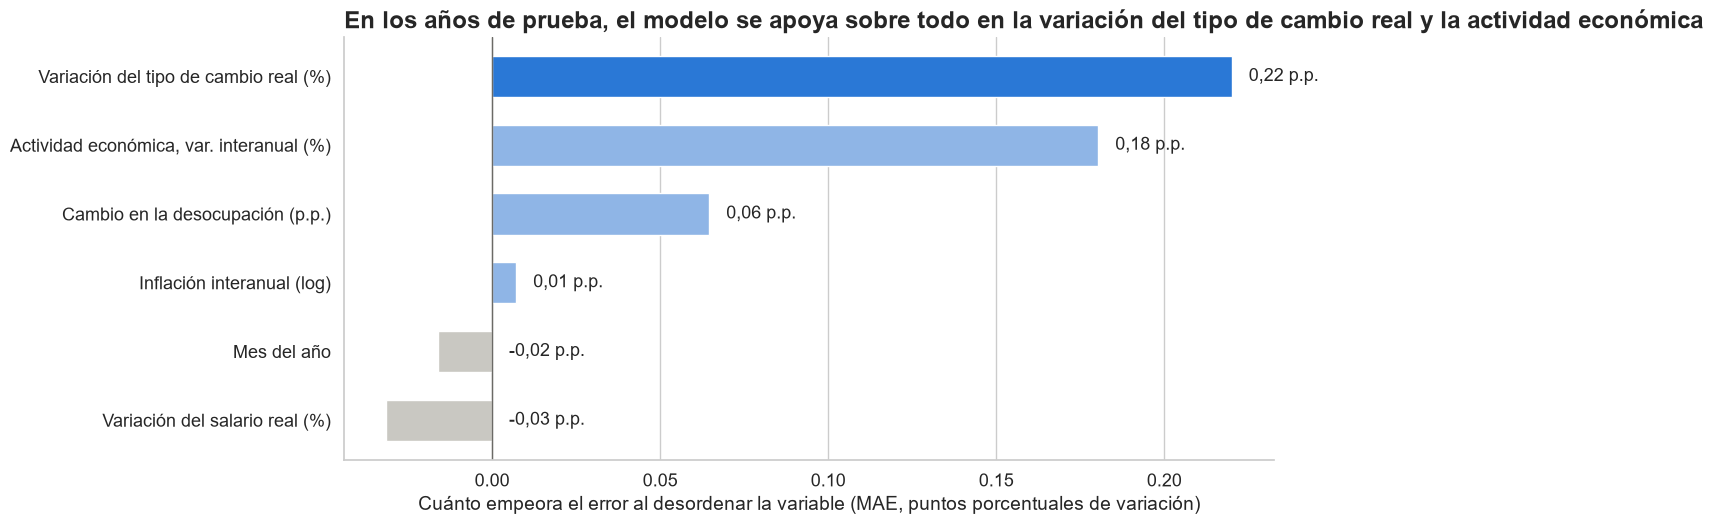

,Mes del año,Variación del salario real (%),Inflación interanual (log),Cambio en la desocupación (p.p.),Variación del tipo de cambio real (%),"Actividad económica, var. interanual (%)"
2014,-0.00,0.00,0.00,0.25,0.05,-0.02
2015,-0.03,0.17,0.14,0.46,0.09,0.21
2016,-0.04,-0.01,-0.06,0.11,0.02,-0.13
2017,0.17,0.08,0.02,-0.04,0.06,0.11
2018,-0.26,-0.34,-0.24,0.07,0.73,1.65
2019,0.01,-0.06,0.00,-0.07,0.61,1.07
2023,-0.03,-0.41,0.00,-0.11,-0.27,-1.34
2024,0.09,-0.28,0.02,-0.08,-0.09,0.08
2025,-0.05,0.57,0.19,-0.00,0.79,-0.01


In [12]:
importancias, arboles_gb = [], {}
for anio in ANIOS_BACKTEST:
    train, test = d[d.index.year < anio], d[d.index.year == anio]
    modelos = modelos_demanda()
    m = modelos["Random Forest"].fit(train[FEATURES], train.var_viajeros)
    r = permutation_importance(m, test[FEATURES], test.var_viajeros, n_repeats=20, random_state=SEMILLA,
                               scoring="neg_mean_absolute_error")
    importancias.append(pd.Series(r.importances_mean, index=FEATURES, name=anio))
    arboles_gb[anio] = modelos["Gradient Boosting"].fit(train[FEATURES], train.var_viajeros).n_estimators_
imp = pd.concat(importancias, axis=1)
imp_media = imp.mean(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(12, 5.5))
colores = [AZUL if v == imp_media.max() else (GRIS_CLARO if v <= 0 else "#8fb5e6") for v in imp_media]
ax.barh([NOMBRES[f] for f in imp_media.index], imp_media.values, color=colores, height=0.6)
for i, v in enumerate(imp_media.values):
    ax.text(max(v, 0) + 0.005, i, f"{v:.2f}".replace(".", ",") + " p.p.", va="center", fontsize=13)
ax.axvline(0, color=GRIS, lw=1)
ax.set_xlabel("Cuánto empeora el error al desordenar la variable (MAE, puntos porcentuales de variación)")
ax.grid(axis="y", visible=False)
corto = {f: NOMBRES[f].split(",")[0].split(" (")[0].lower() for f in FEATURES}
ax.set_title(f"En los años de prueba, el modelo se apoya sobre todo en la {corto[imp_media.index[-1]]} y la {corto[imp_media.index[-2]]}")
plt.show()
(imp.T.rename(columns=NOMBRES)).round(2)

**Lectura de negocio.** Cuando hay que anticipar un año nuevo, las señales que más usa el modelo son **el tipo de cambio real (las devaluaciones) y la actividad económica**: son las que le permitieron ver venir las caídas de 2018–2019 y la recuperación de 2025 (ver la tabla por año). El salario real es el primer corte del árbol, pero en prueba su información se superpone con la del dólar: cada devaluación fuerte vino con caída del salario real, y el modelo puede usar cualquiera de las dos. La importancia **cambia mucho de un año a otro**: en 2023 desordenar la actividad hasta *mejora* el error, porque ese año la demanda la movió PreViaje y no la economía. **Ojo: esto no es causal ni tiene signo.** Dice “sin esta variable el modelo predice peor”, no “si sube el salario, sube la demanda en tal cantidad” (para eso está la regresión lineal y el análisis de sensibilidad del notebook 03). Variables que se mueven juntas (salario, inflación, desocupación) se “reparten” la importancia.

### Gradient Boosting con *early stopping*

El *boosting* agrega árboles chicos (profundidad 3) en secuencia. Si se lo deja, sigue agregando hasta memorizar el ruido; con ***early stopping*** se reserva el 20 % del entrenamiento y se frena cuando 50 árboles seguidos no mejoran ese 20 %.

In [13]:
gb_final = modelos_demanda()["Gradient Boosting"].fit(d[FEATURES], d.var_viajeros)
arboles = pd.Series({**arboles_gb, "Modelo final (todos los años)": gb_final.n_estimators_}, name="Árboles usados de 1.000 posibles")
print(f"El early stopping frenó entre {min(arboles_gb.values())} y {max(arboles_gb.values())} árboles según el año: "
      "nunca necesitó los 1.000.")
arboles.to_frame().T

El early stopping frenó entre 66 y 172 árboles según el año: nunca necesitó los 1.000.


,2014,2015,2016,2017,2018,2019,2023,2024,2025,Modelo final (todos los años)
Árboles usados de 1.000 posibles,99,66,153,172,73,74,172,162,149,342


**Qué leemos.** Con *early stopping* el *boosting* no sobreajusta, pero igual queda en **6,3 %**, empatado con la regla simple. Con ~180 meses de historia, la diferencia entre *ensembles* cae dentro del ruido: no vale la pena complicarse más.

### Regresión lineal: el complemento interpretable

La regresión lineal tiene más error, pero dice **para qué lado y cuánto** mueve cada variable, en unidades que se entienden. (Los coeficientes de los meses solo capturan diferencias de estacionalidad y se omiten.)

In [14]:
lineal = modelos_demanda()["Regresión lineal"].fit(d[FEATURES], d.var_viajeros)
macro = FEATURES[1:]
escala = lineal[0].named_transformers_["remainder"].scale_
coef = pd.Series(lineal[-1].coef_[-len(macro):], index=macro) / escala  # por unidad original
cambios = {"salario_real_var": (1, "El salario real crece 1 % más"),
           "inflacion_log": (np.log(2), "La inflación interanual se duplica (ej. 30 % → 60 %)"),
           "desocupacion_var": (1, "La desocupación sube 1 punto"),
           "tipo_cambio_real_var": (10, "El dólar real sube 10 %"),
           "emae_interanual": (1, "La actividad crece 1 punto más")}
coeficientes = pd.DataFrame([{"Si…": txt, "…la variación de viajeros cambia (p.p.)": round(coef[f] * u, 2)}
                             for f, (u, txt) in cambios.items()])
coeficientes

,Si…,…la variación de viajeros cambia (p.p.)
0,El salario real crece 1 % más,0.29
1,La inflación interanual se duplica (ej. 30 % →...,-1.01
2,La desocupación sube 1 punto,-1.73
3,El dólar real sube 10 %,0.75
4,La actividad crece 1 punto más,0.45


**Qué leemos.** Los signos son los que espera cualquiera que conozca el negocio: **más salario real y más actividad → más viajeros; más inflación y más desocupación → menos**. Un dólar real más caro empuja algo de demanda hacia el turismo interno (viajar afuera se encarece). Esto le da credibilidad al modelo de árboles, que llega a conclusiones parecidas por otro camino.

## ¿Por qué Random Forest y no otro?

In [15]:
arbol_prof = curva_det[curva_det.profundidad == PROF].set_index("anio")["Prueba"]
comp = tabla[años].copy()
comp.loc[f"Árbol de decisión (profundidad {PROF}, de la curva)"] = arbol_prof.reindex(años).values
comparacion = pd.DataFrame({
    "MAPE promedio (%)": comp.mean(axis=1),
    "Peor año (%)": comp.max(axis=1),
    "Desvío entre años (p.p.)": comp.std(axis=1),
    "Años que le gana al baseline (de 9)": [(comp.loc[m] < comp.loc[BASE]).sum() for m in comp.index],
})
comparacion.loc[BASE, "Años que le gana al baseline (de 9)"] = np.nan
rol = {"Random Forest": "Pronóstico (elegido)", "Gradient Boosting": "Descartado: más complejo, no mejora",
       "Árbol de decisión": "Explicar con reglas", BASE: "Piso de comparación", "Regresión lineal": "Signos y extrapolación",
       f"Árbol de decisión (profundidad {PROF}, de la curva)": "Explicar con reglas"}
comparacion["Rol"] = [rol[m] for m in comparacion.index]
comparacion.sort_values("MAPE promedio (%)").round(1)

,MAPE promedio (%),Peor año (%),Desvío entre años (p.p.),Años que le gana al baseline (de 9),Rol
"Árbol de decisión (profundidad 2, de la curva)",5.9,14.3,3.4,6.0,Explicar con reglas
Random Forest,6.0,14.4,3.6,6.0,Pronóstico (elegido)
Baseline (mismo mes año anterior),6.3,14.8,3.4,NaN,Piso de comparación
Gradient Boosting,6.3,13.5,3.1,6.0,"Descartado: más complejo, no mejora"
Árbol de decisión,6.6,15.4,3.6,6.0,Explicar con reglas
Regresión lineal,8.9,26.9,7.7,5.0,Signos y extrapolación


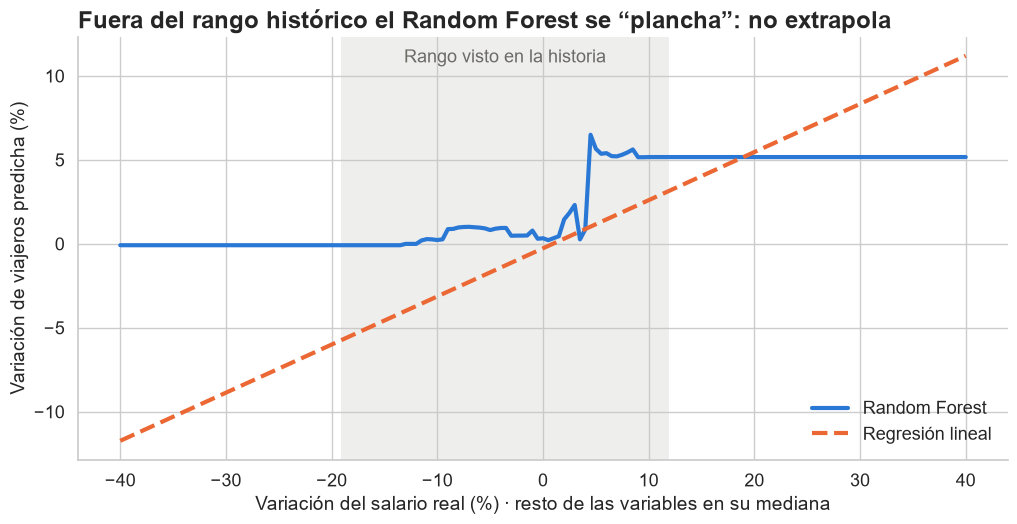

In [16]:
# Los árboles no extrapolan: qué predice cada modelo si el salario real se sale del rango histórico
grilla = pd.DataFrame({f: d[f].median() for f in FEATURES}, index=range(161))
grilla["mes"] = 1
grilla["salario_real_var"] = np.linspace(-40, 40, 161)
fig, ax = plt.subplots(figsize=(12, 5.5))
lo, hi = d.salario_real_var.min(), d.salario_real_var.max()
ax.axvspan(lo, hi, color=GRIS_CLARO, alpha=0.3, lw=0)
ax.text((lo + hi) / 2, 0.97, "Rango visto en la historia", transform=ax.get_xaxis_transform(), ha="center", va="top",
        fontsize=13, color=GRIS)
ax.plot(grilla.salario_real_var, rf.predict(grilla[FEATURES]), color=AZUL, lw=3, label="Random Forest")
ax.plot(grilla.salario_real_var, lineal.predict(grilla[FEATURES]), color=NARANJA, lw=3, ls="--", label="Regresión lineal")
ax.set_xlabel("Variación del salario real (%) · resto de las variables en su mediana")
ax.set_ylabel("Variación de viajeros predicha (%)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Fuera del rango histórico el Random Forest se “plancha”: no extrapola")
plt.show()

**La decisión, en términos de negocio:**

1. **Le gana a la regla simple** en promedio y, sobre todo, **en los años de crisis**, que es cuando un error de planificación cuesta más (personal contratado de más, cupos sin vender o, al revés, demanda que no se puede atender).
2. **Es estable**: no depende de un único corte como el árbol. El árbol podado a 2 niveles tiene un error parecido (5,9 %, algo optimista porque su profundidad se eligió mirando esos mismos años), pero un árbol cambia mucho si se agregan unos pocos meses (es *inestable*); el promedio de 500 árboles no.
3. **No necesita supuestos de línea recta**: capta efectos que se activan solo pasado un umbral (por ejemplo, la inflación hace daño cuando se dispara).
4. **Su limitación está acotada por diseño**: no extrapola fuera del rango histórico, pero como predecimos **variaciones** (que sí se mantienen en rango) y no niveles, eso no lo afecta en escenarios razonables. Para escenarios extremos, se contrasta con la **regresión lineal**, que sí extrapola.

**Qué aporta cada modelo** (combinar y justificar): la **línea base** es el piso; el **Random Forest** da el número; el **árbol** da las reglas para contarlo; la **regresión lineal** da los signos y el chequeo en escenarios extremos; el **boosting** confirma que complicarse más no mejora.

---

## Clasificador: ¿qué turista se aloja en hotel?

**Datos:** microdatos de la EVyTH (2012 a 2024-T2), un registro por persona y viaje, **ponderado por el factor de expansión** (`pondera`) para que represente a la población. **Partición temporal:** se entrena hasta 2021 y se prueba en 2022–2024 (viajes posteriores, como en la vida real). Ambos modelos usan `class_weight="balanced"` porque solo ~1 de cada 4 viajes va a hotel.

In [17]:
ev = cargar_evyth()
X_tr, y_tr, w_tr, X_te, y_te, w_te = datos_hotel(ev)
arbol_h, rf_h = cargar("hotel_arbol.joblib"), cargar("hotel_rf.joblib")
p_arbol, p_rf = arbol_h.predict_proba(X_te)[:, 1], rf_h.predict_proba(X_te)[:, 1]
tasa = np.average(y_te, weights=w_te)
print(f"Viajes de entrenamiento: {miles(len(X_tr))} · de prueba: {miles(len(X_te))}")
print(f"En 2022–2024, {pct(tasa * 100, 0)} de los viajes se alojó en hotel.")
print(f"Piso (decir siempre 'no hotel'): exactitud {pct((1 - tasa) * 100, 0)} pero no encuentra a ningún huésped; AUC 0,50")
pd.DataFrame({"AUC en prueba": [roc_auc_score(y_te, p, sample_weight=w_te) for p in (p_arbol, p_rf)]},
             index=["Árbol de decisión", "Random Forest"]).round(3)

Viajes de entrenamiento: 198.620 · de prueba: 43.447
En 2022–2024, 24 % de los viajes se alojó en hotel.
Piso (decir siempre 'no hotel'): exactitud 76 % pero no encuentra a ningún huésped; AUC 0,50


,AUC en prueba
Árbol de decisión,0.742
Random Forest,0.782


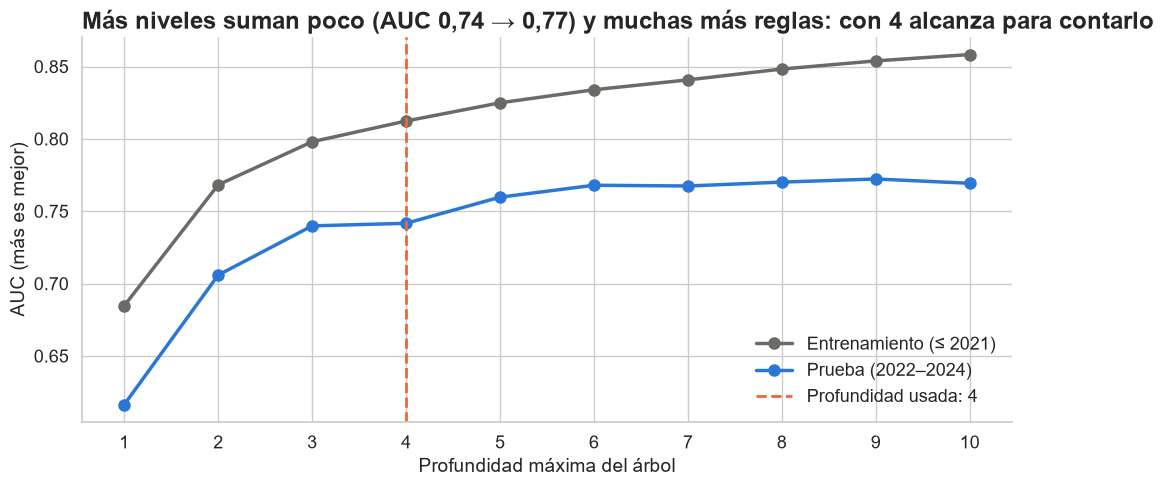

profundidad,1,2,3,4,5,6,7,8,9,10
Entrenamiento,0.685,0.768,0.798,0.812,0.825,0.834,0.841,0.848,0.854,0.858
Prueba,0.616,0.706,0.740,0.742,0.760,0.768,0.767,0.770,0.772,0.769


In [18]:
# Profundidad del árbol de hotel: misma lógica de la curva train vs. prueba
filas = []
for p in range(1, 11):
    m = DecisionTreeClassifier(max_depth=p, min_samples_leaf=200, class_weight="balanced", random_state=SEMILLA)
    m.fit(X_tr, y_tr, sample_weight=w_tr)
    filas.append({"profundidad": p,
                  "Entrenamiento": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1], sample_weight=w_tr),
                  "Prueba": roc_auc_score(y_te, m.predict_proba(X_te)[:, 1], sample_weight=w_te)})
curva_h = pd.DataFrame(filas).set_index("profundidad")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(curva_h.index, curva_h["Entrenamiento"], color=GRIS, lw=2.5, marker="o", ms=8, label="Entrenamiento (≤ 2021)")
ax.plot(curva_h.index, curva_h["Prueba"], color=AZUL, lw=2.5, marker="o", ms=8, label="Prueba (2022–2024)")
ax.axvline(arbol_h.get_depth(), color=NARANJA, ls="--", lw=2, label=f"Profundidad usada: {arbol_h.get_depth()}")
ax.set_xlabel("Profundidad máxima del árbol"); ax.set_ylabel("AUC (más es mejor)")
ax.set_xticks(curva_h.index); ax.legend(frameon=False, loc="lower right")
ax.set_title("Más niveles suman poco (AUC 0,74 → 0,77) y muchas más reglas: con 4 alcanza para contarlo")
plt.show()
curva_h.round(3).T

### Matriz de confusión: los dos errores no cuestan lo mismo

Usamos el clasificador para **decidir a quién dirigir una promoción de hotel**:

- **Falso positivo** (el modelo dice “hotel” y la persona no iba a ir): se le manda una promoción que no usa. **Costo bajo**: el costo del contacto o del anuncio.
- **Falso negativo** (el modelo dice “no hotel” y la persona sí iba): **perdemos a un huésped** que podría haber elegido nuestra cadena. **Costo alto**: una estadía entera de ingresos.

Por eso conviene un modelo que **encuentre a la mayoría de los huéspedes** (*recall* alto), aunque algunas promociones se “desperdicien” (*precisión* más baja).

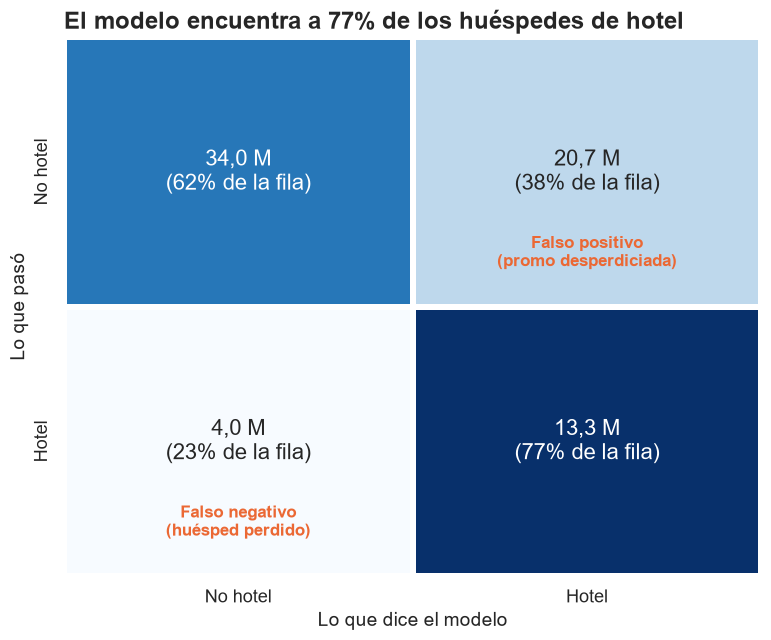

Viajes expandidos a la población (millones de viajes-persona, 2022–2024). Random Forest, umbral 0,5.


In [19]:
UMBRAL = 0.5
pred = (p_rf >= UMBRAL).astype(int)
cm = confusion_matrix(y_te, pred, sample_weight=w_te)
etiquetas = ["No hotel", "Hotel"]
texto = np.array([[f"{millones(cm[i, j], 1)}\n({cm[i, j] / cm[i].sum():.0%} de la fila)" for j in range(2)] for i in range(2)])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=texto, fmt="", cmap="Blues", cbar=False, linewidths=3,
            linecolor="white", annot_kws={"size": 16}, xticklabels=etiquetas, yticklabels=etiquetas, ax=ax)
ax.set_xlabel("Lo que dice el modelo"); ax.set_ylabel("Lo que pasó")
ax.set_title(f"El modelo encuentra a {cm[1, 1] / cm[1].sum():.0%} de los huéspedes de hotel")
for (i, j), nombre in {(0, 1): "Falso positivo\n(promo desperdiciada)", (1, 0): "Falso negativo\n(huésped perdido)"}.items():
    ax.text(j + 0.5, i + 0.85, nombre, ha="center", fontsize=12, color=NARANJA, fontweight="bold")
plt.show()
print("Viajes expandidos a la población (millones de viajes-persona, 2022–2024). Random Forest, umbral 0,5.")

In [20]:
filas = []
for u in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pr = (p_rf >= u).astype(int)
    filas.append({"Umbral": u,
                  "Huéspedes encontrados (recall)": recall_score(y_te, pr, sample_weight=w_te),
                  "De cada 100 promos, cuántas llegan a un huésped (precisión)": precision_score(y_te, pr, sample_weight=w_te) * 100,
                  "% de viajeros a contactar": np.average(pr, weights=w_te) * 100})
umbrales = pd.DataFrame(filas).set_index("Umbral")
umbrales["Huéspedes encontrados (recall)"] *= 100
umbrales.round(0)

,Huéspedes encontrados (recall),"De cada 100 promos, cuántas llegan a un huésped (precisión)",% de viajeros a contactar
Umbral,,,
0.3,92.0,32.0,69.0
0.4,87.0,35.0,60.0
0.5,77.0,39.0,47.0
0.6,65.0,48.0,33.0
0.7,47.0,56.0,20.0


**Qué leemos.** Con el umbral 0,5 el modelo encuentra a **casi 8 de cada 10 huéspedes** contactando a menos de la mitad de los viajeros; 4 de cada 10 promociones llegan a alguien que efectivamente se aloja en hotel (contra 2,4 de cada 10 si se mandaran al azar). Si la promoción es barata (mail, redes), conviene **bajar el umbral** y llegar a más huéspedes; si es cara (descuento fuerte), **subirlo**.

### Reglas del árbol: los segmentos, en castellano

In [21]:
REGION = {1: "CABA", 2: "partidos del GBA", 3: "resto de Prov. de Bs. As.", 4: "Centro", 5: "Litoral", 6: "Norte",
          7: "Cuyo", 8: "Patagonia"}
MOTIVO = {1: "ocio", 2: "visita a familiares/amigos", 3: "trabajo", 4: "estudios", 5: "salud", 6: "religioso",
          7: "compras", 8: "otros", 99: "sin dato"}
TRANSPORTE = {1: "auto propio", 2: "ómnibus", 3: "tren", 4: "avión", 5: "embarcación", 6: "taxi/remís", 8: "otro",
              99: "sin dato"}
GRUPO = {1: "1-2 personas", 2: "3-4 personas", 3: "5 o más personas"}
CATEGORICAS = {"region_destino": ("destino", REGION), "region_origen": ("origen", REGION), "motivo": ("motivo", MOTIVO),
               "transporte": ("transporte", TRANSPORTE), "tamanio_grupo": ("grupo", GRUPO),
               "quintil": ("quintil de ingreso", {i: str(i) for i in range(1, 6)}),
               "trimestre": ("trimestre", {i: str(i) for i in range(1, 5)})}

def condicion_hotel(f, lo, hi):
    if f in CATEGORICAS:
        nombre, mapa = CATEGORICAS[f]
        valores = [v for k, v in mapa.items() if lo < k <= hi]
        if len(valores) == len(mapa) - 1 and f in ("motivo", "transporte"):
            excluido = [v for k, v in mapa.items() if not (lo < k <= hi)][0]
            return f"{nombre}: cualquiera menos {excluido}"
        return f"{nombre}: " + (", ".join(valores[:-1]) + " o " + valores[-1] if len(valores) > 1 else valores[0])
    if f == "noches":
        if np.isinf(lo): return f"≤ {int(hi)} noches"
        if np.isinf(hi): return f"≥ {int(lo) + 1} noches"
        return f"entre {int(lo) + 1} y {int(hi)} noches"
    return f"{f} en ({lo}, {hi}]"

hoja_te = arbol_h.apply(X_te)
stats = pd.DataFrame({"hoja": hoja_te, "w": w_te.values, "hotel": y_te.values})
stats = stats.groupby("hoja").apply(lambda g: pd.Series({"% de los viajes": g.w.sum() / w_te.sum() * 100,
                                                         "% en hotel (2022–2024)": np.average(g.hotel, weights=g.w) * 100}))
filas = [{"hoja": n, "Regla": "Si " + " · ".join(condicion_hotel(f, *v) for f, v in cond.items())}
         for n, cond in hojas(arbol_h, FEATURES_HOTEL)]
reglas_hotel = pd.DataFrame(filas).set_index("hoja").join(stats).sort_values("% en hotel (2022–2024)", ascending=False)
hot = reglas_hotel["% en hotel (2022–2024)"]
reglas_hotel["Veces el promedio"] = (hot / (tasa * 100)).round(1)
reglas_hotel["Decisión"] = np.select([hot >= 2 * tasa * 100, hot >= tasa * 100], ["Prioridad alta", "Prioridad media"], "No apuntar")
with pd.option_context("display.max_colwidth", None):
    display(reglas_hotel.round(1).style.hide(axis="index").format(precision=1)
            .set_properties(**{"text-align": "left", "font-size": "13px"}))

Regla,% de los viajes,% en hotel (2022–2024),Veces el promedio,Decisión
"Si motivo: ocio · transporte: cualquiera menos auto propio · destino: Centro, Litoral, Norte, Cuyo o Patagonia · quintil de ingreso: 4 o 5",5.9,66.3,2.8,Prioridad alta
"Si motivo: ocio · transporte: cualquiera menos auto propio · destino: Centro, Litoral, Norte, Cuyo o Patagonia · quintil de ingreso: 1, 2 o 3",3.6,53.0,2.2,Prioridad alta
"Si motivo: trabajo, estudios, salud, religioso o compras · grupo: 1-2 personas o 3-4 personas",2.9,43.1,1.8,Prioridad media
"Si motivo: ocio · transporte: ómnibus, tren o avión · destino: CABA, partidos del GBA o resto de Prov. de Bs. As.",5.5,40.5,1.7,Prioridad media
"Si motivo: ocio · transporte: embarcación, taxi/remís, otro o sin dato · destino: CABA, partidos del GBA o resto de Prov. de Bs. As.",0.2,39.7,1.7,Prioridad media
"Si motivo: ocio · transporte: auto propio · destino: Centro, Litoral, Norte, Cuyo o Patagonia · ≥ 3 noches",17.8,32.7,1.4,Prioridad media
"Si motivo: ocio · transporte: auto propio · destino: Centro, Litoral, Norte, Cuyo o Patagonia · ≤ 2 noches",10.0,25.0,1.0,Prioridad media
Si motivo: visita a familiares/amigos · quintil de ingreso: 1 o 2 · destino: Cuyo o Patagonia,1.1,23.9,1.0,No apuntar
"Si motivo: otros o sin dato · origen: resto de Prov. de Bs. As., Centro, Litoral, Norte, Cuyo o Patagonia",1.0,19.9,0.8,No apuntar
"Si motivo: ocio · transporte: auto propio · destino: CABA, partidos del GBA o resto de Prov. de Bs. As. · ≤ 10 noches",23.0,18.4,0.8,No apuntar


**Las reglas que importan para la Gerencia Comercial:**

Porcentajes medidos en 2022–2024 (datos de prueba); el promedio general es 24 %.

1. **Si el viaje es de ocio, al interior del país (Centro, Litoral, Norte, Cuyo o Patagonia), sin auto propio (ómnibus, avión…) y de un hogar de quintil 4 o 5 → 2 de cada 3 van a hotel** (66 %, casi el triple del promedio). Es el **segmento núcleo**: turismo de ocio de ingresos medios-altos que llega en transporte público o avión.
2. **El mismo viaje en hogares de quintiles 1 a 3 → 1 de cada 2 va a hotel** (53 %). Sin auto, en el interior, el hotel es la opción natural aunque el ingreso sea menor: público para tarifas promocionales.
3. **Si el viaje es por trabajo, estudios, salud o similares y viajan hasta 4 personas → 43 % en hotel.** Segmento corporativo, menos estacional: sirve para llenar la temporada baja.
4. **Si es de ocio y en auto propio → entre 8 % y 33 % en hotel** según destino y noches: compite con la vivienda alquilada por temporada y la segunda vivienda. Es el segmento más grande (más de la mitad de los viajes): ahí se gana **convirtiendo** con precio o paquetes.
5. **Si el motivo es visitar a familiares o amigos → casi nunca hotel** (entre 2 % y 6 % en la mayoría de los casos). No es el público de una promo de hotel.

### Importancia por permutación (Random Forest de hotel)

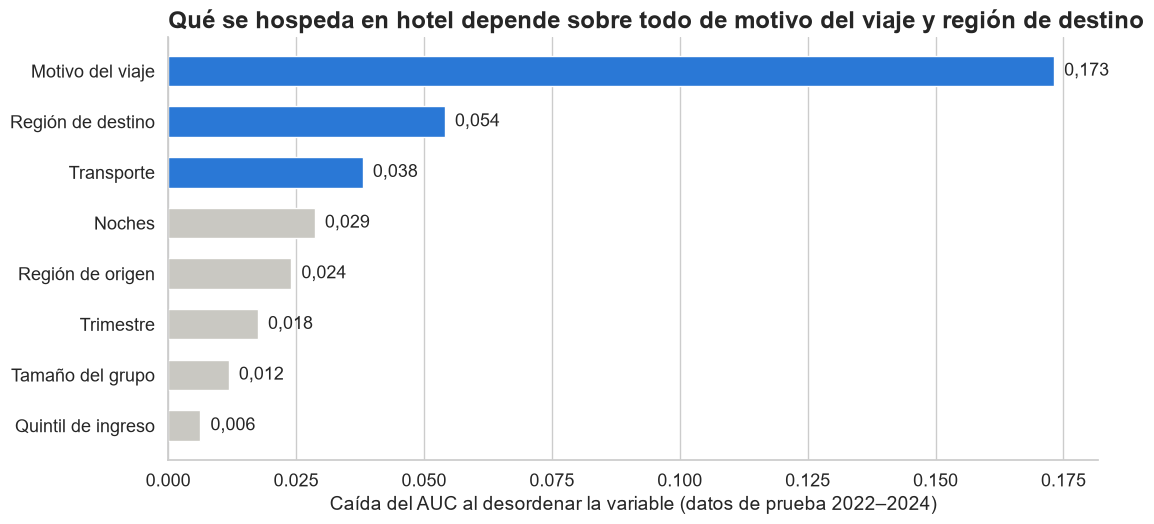

In [22]:
NOMBRES_HOTEL = {"quintil": "Quintil de ingreso", "region_origen": "Región de origen", "region_destino": "Región de destino",
                 "trimestre": "Trimestre", "noches": "Noches", "tamanio_grupo": "Tamaño del grupo", "motivo": "Motivo del viaje",
                 "transporte": "Transporte"}
muestra = X_te.sample(10000, random_state=SEMILLA).index
r = permutation_importance(rf_h, X_te.loc[muestra], y_te.loc[muestra], sample_weight=w_te.loc[muestra], scoring="roc_auc",
                           n_repeats=5, random_state=SEMILLA, n_jobs=-1)
imp_h = pd.Series(r.importances_mean, index=FEATURES_HOTEL).sort_values()
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.barh([NOMBRES_HOTEL[f] for f in imp_h.index], imp_h.values, height=0.6,
        color=[AZUL if v >= imp_h.nlargest(3).min() else GRIS_CLARO for v in imp_h])
for i, v in enumerate(imp_h.values):
    ax.text(v + 0.002, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=13)
ax.set_xlabel("Caída del AUC al desordenar la variable (datos de prueba 2022–2024)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Qué se hospeda en hotel depende sobre todo de {NOMBRES_HOTEL[imp_h.index[-1]].lower()} y {NOMBRES_HOTEL[imp_h.index[-2]].lower()}")
plt.show()

**Lectura de negocio.** El **para qué** viaja la gente (motivo) pesa muchísimo más que cualquier otra cosa: quien visita familia no va a hotel aunque tenga ingresos altos. Después vienen **adónde** va y **en qué** viaja. El quintil de ingreso casi no suma una vez que se conocen motivo, destino y transporte, porque esas variables ya lo reflejan (quien vuela al Norte de vacaciones suele ser de ingresos altos). Como antes: **no es causal** — no dice que subirle el ingreso a alguien lo mande a un hotel, sino qué datos ayudan a reconocer a un huésped probable.

### Segmentos: % de viajes que se alojan en hotel, por quintil de ingreso y región de destino

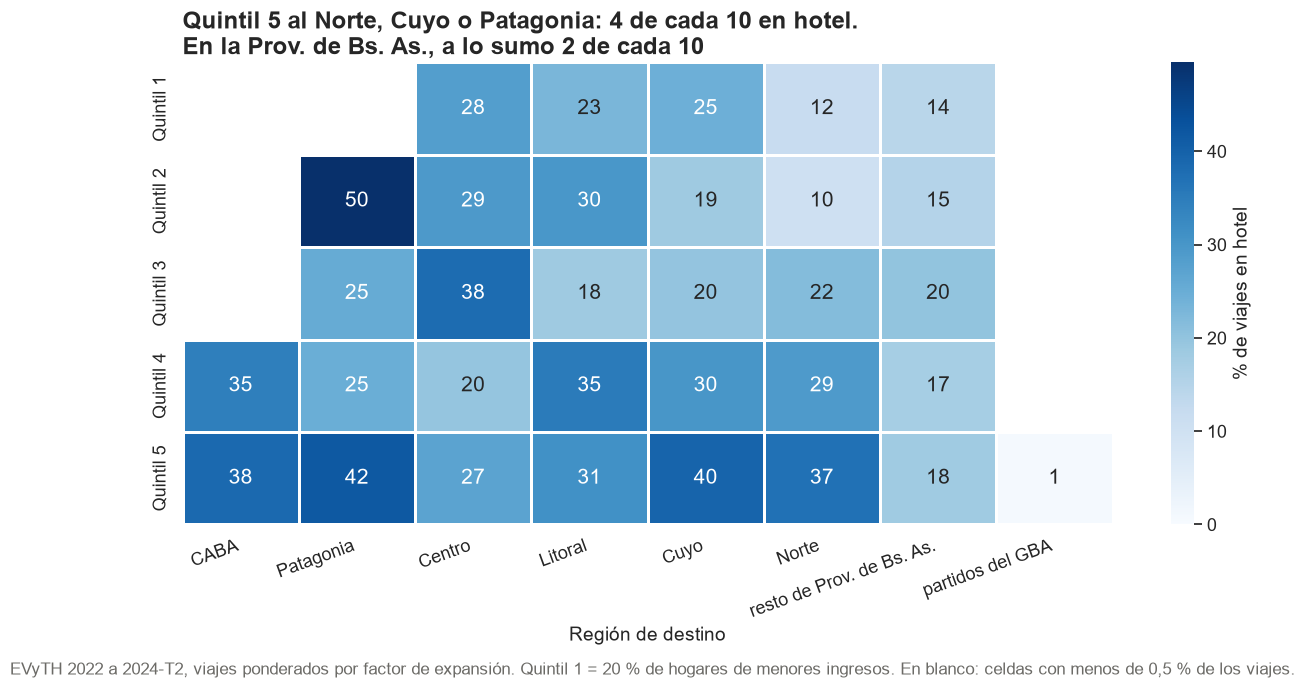

Peso de cada segmento en el total de viajes (%), para dimensionar la promoción:


Destino,CABA,Patagonia,Centro,Litoral,Cuyo,Norte,resto de Prov. de Bs. As.,partidos del GBA
Quintil 1,0.2,0.4,0.7,0.9,0.8,1.1,2.6,0.1
Quintil 2,0.2,0.8,1.1,1.5,0.8,2.5,3.6,0.1
Quintil 3,0.4,0.9,2.3,2.9,1.4,2.0,6.3,0.2
Quintil 4,0.6,1.9,3.7,3.9,1.6,2.1,9.6,0.5
Quintil 5,1.5,4.4,5.3,6.6,2.6,3.4,16.4,2.3


In [23]:
reciente = ev[ev.anio >= 2022].copy()
reciente["Destino"] = reciente.region_destino.map(REGION)
seg = (reciente.groupby(["quintil", "Destino"])
       .apply(lambda g: np.average(g.hotel, weights=g.pondera) * 100).unstack())
orden_dest = seg.mean().sort_values(ascending=False).index
seg = seg[orden_dest]
seg.index = [f"Quintil {q}" for q in seg.index]
volumen = (reciente.groupby(["quintil", "Destino"]).pondera.sum().unstack()[orden_dest] / reciente.pondera.sum() * 100)
volumen.index = seg.index
seg = seg.where(volumen >= 0.5).dropna(axis=1, how="all")  # celdas con muy pocos viajes: no se muestran

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(seg, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=np.nanmax(seg.values), linewidths=2, linecolor="white",
            cbar_kws={"label": "% de viajes en hotel"}, annot_kws={"size": 15}, ax=ax)
ax.set_xlabel("Región de destino"); ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.grid(False)
ax.set_title("Quintil 5 al Norte, Cuyo o Patagonia: 4 de cada 10 en hotel.\nEn la Prov. de Bs. As., a lo sumo 2 de cada 10")
fig.text(0.01, -0.14, "EVyTH 2022 a 2024-T2, viajes ponderados por factor de expansión. Quintil 1 = 20 % de hogares de menores ingresos. En blanco: celdas con menos de 0,5 % de los viajes.",
         fontsize=12, color=GRIS)
fig.savefig(IMG / "segmentos_hotel.png")
plt.show()

print("Peso de cada segmento en el total de viajes (%), para dimensionar la promoción:")
volumen.round(1)

**Qué leemos.** En el **Norte, Cuyo y Litoral el uso de hotel crece con el ingreso** (en el Norte pasa de 12 % en el quintil 1 a 37 % en el quintil 5). La **Patagonia** es “hotelera” en casi todos los quintiles (destino lejano, sin casa de familia ni segunda vivienda a mano). En la **Provincia de Buenos Aires** (Costa Atlántica incluida) el hotel no pasa de 2 de cada 10 en ningún quintil: dominan la vivienda alquilada por temporada y la segunda vivienda. La tabla de volumen recuerda que el segmento más “hotelero” no siempre es el más grande: la Costa Atlántica (resto de Prov. de Bs. As.) aporta muchos viajes aunque pocos vayan a hotel, así que ahí la estrategia es **convertir** (precio, paquetes) más que **retener**.

---

## Cierre del notebook

| Fase CRISP-DM | Qué hicimos | Resultado |
|---|---|---|
| 3 · Preparación | *Target* = variación interanual; features = cambios macro de 12 meses; pandemia excluida | 181 meses utilizables, 6 predictores |
| 4 · Modelado | Línea base, lineal, árbol (profundidad por curva), Random Forest (OOB), Gradient Boosting (*early stopping*); árbol + RF para hotel | 5 modelos de demanda, 2 de hotel |
| 5 · Evaluación | *Backtest walk-forward* en 9 años; matriz de confusión con costo FP/FN; importancia por permutación | RF 6,0 % vs. 6,3 % de la regla simple; hotel AUC 0,78, encuentra 77 % de los huéspedes |

**Qué se nos escapa** (y motiva el notebook 03): el modelo dice cuánto se equivocó en el pasado, pero la gerencia necesita **el número del próximo verano** y **qué pasa si la economía empeora**. Eso es la proyección con escenarios.